# MangoLeaf AI — Rejection Threshold Fitting (v2.1.1)

**This notebook does not train anything.** It loads the model that is already shipped
in the app and measures how it behaves on out-of-scope photographs, so that the margin
and entropy thresholds can be filled in.

No weight is changed. Test accuracy stays 97.12%. The only file this produces is a
replacement `public/model/model_config.json`.

### What it needs in Google Drive

```
MyDrive/
  mangoleaf_v2_1/resume/
    mangoleaf_v2_1_calibrated.keras     34.70 MB
    y_prob_cal.npy
    y_true.npy
    resume_info.json
  mango_ood_test/                        168 non-mango photographs
```

Both already exist. `resume/` was written by the last cell of the training run;
`mango_ood_test/` is the folder you gathered.

### How to run

Runtime → Run all. Five code cells, in order:

| Cell | What it does |
| :-- | :-- |
| 1 | mounts Drive, loads the shipped model and saved test predictions |
| 2 | splits the 168 out-of-scope images 84 / 84 with seed 42 |
| 3 | runs `model.predict` on both halves, draws the three histograms |
| 4 | sweeps margin and entropy, prints the fitted thresholds |
| 5 | writes the new `model_config.json` and prints it for copy-paste |

Confidence stays pinned at **0.70**. It is a manuscript claim cited to [31] and no
cell in this notebook touches it. Only margin and entropy are fitted.

**Do not** run `MangoLeaf_AI_Training_v2_1_Post_Training.ipynb` again — it holds the
figures and tables the manuscript cites, and a rerun would overwrite them with
different numbers.

In [1]:
# ============================================================================
# CELL 1 — RESUME. No training. Weights are loaded, never fitted.
# Replaces cells #1 through #22 of the training notebook.
# ============================================================================
import os, json, random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import accuracy_score

from google.colab import drive
drive.mount("/content/drive")

# ---- constants copied verbatim from cell #3 of the training notebook --------
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

OOD_DIR    = "/content/drive/MyDrive/mango_ood_test"
DRIVE_SAVE = "/content/drive/MyDrive/mangoleaf_v2_1"
RESUME_DIR = os.path.join(DRIVE_SAVE, "resume")

IMG_SIZE = (224, 224)
IMG_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

CONFIDENCE_THRESHOLD = 0.70   # FIXED BY THE MANUSCRIPT. Never tuned.
MIN_ID_RETENTION     = 0.95   # keep at least 95% of real mango scans

CLASS_NAMES = ["anthracnose", "bacterial_black_spot", "bacterial_canker",
               "healthy", "mango_scab", "sooty_mold"]

FIG_DIR = "/content/figures"
FIG_DPI = 150
os.makedirs(FIG_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)

# ---- check the resume files are actually there ------------------------------
NEEDED = ["mangoleaf_v2_1_calibrated.keras", "y_prob_cal.npy",
          "y_true.npy", "resume_info.json"]
missing = [f for f in NEEDED if not os.path.exists(os.path.join(RESUME_DIR, f))]
if missing:
    raise FileNotFoundError(
        "Missing from {}: {}\n"
        "These were written by the last cell of the training run. Without them "
        "this notebook cannot resume.".format(RESUME_DIR, ", ".join(missing)))

with open(os.path.join(RESUME_DIR, "resume_info.json")) as f:
    resume_info = json.load(f)

# compile=False — only predict is needed, and it skips optimizer deserialisation.
model      = tf.keras.models.load_model(
                 os.path.join(RESUME_DIR, "mangoleaf_v2_1_calibrated.keras"),
                 compile=False)
y_prob_cal = np.load(os.path.join(RESUME_DIR, "y_prob_cal.npy"))
y_true     = np.load(os.path.join(RESUME_DIR, "y_true.npy"))

# ---- verify the right artefacts were resumed --------------------------------
assert y_prob_cal.shape[1] == len(CLASS_NAMES), "class count mismatch"
assert y_prob_cal.shape[0] == y_true.shape[0],  "prob / label length mismatch"
assert resume_info["classes"] == CLASS_NAMES,   "class order mismatch"
assert resume_info["temperatureFoldedIntoWeights"] is True

reloaded_acc = accuracy_score(y_true, y_prob_cal.argmax(axis=1))

print("")
print("=" * 64)
print("RESUMED WITHOUT RETRAINING")
print("=" * 64)
print("  trial                : {}".format(resume_info["trial"]))
print("  temperature (folded) : {}".format(resume_info["temperature"]))
print("  test accuracy on file: {:.4f}".format(resume_info["testAccuracy"]))
print("  recomputed from .npy : {:.4f}".format(reloaded_acc))
print("  test images          : {}".format(len(y_true)))
print("")
assert abs(reloaded_acc - resume_info["testAccuracy"]) < 1e-4, \
    "accuracy drift — wrong resume files"
print("Match. These are the weights already shipped in the app.")

if os.path.isdir(OOD_DIR):
    n_ood = len([f for f in os.listdir(OOD_DIR) if f.lower().endswith(IMG_EXTS)])
    n_sub = [d for d in sorted(os.listdir(OOD_DIR))
             if os.path.isdir(os.path.join(OOD_DIR, d))]
    print("Out-of-scope folder found. Loose images: {}   Subfolders: {}".format(
        n_ood, n_sub if n_sub else "none"))
else:
    print("WARNING: no folder at", OOD_DIR)
print("")
print("Now run cell 2.")

Mounted at /content/drive
TensorFlow: 2.20.0

RESUMED WITHOUT RETRAINING
  trial                : 2.1
  temperature (folded) : 0.754966
  test accuracy on file: 0.9712
  recomputed from .npy : 0.9712
  test images          : 417

Match. These are the weights already shipped in the app.
Out-of-scope folder found. Loose images: 168   Subfolders: none

Now run cell 2.


## Cells 2 to 4 — Rejection thresholds

This measures the exact behaviour you reported: non-mango images receiving a disease label.

### The three signals

| Signal | What it catches |
| :-- | :-- |
| **confidence** — highest probability | model is unsure overall |
| **margin** — top probability minus second | two classes nearly tied, e.g. 0.71 against 0.28 |
| **entropy** — how evenly probability spreads | probability smeared thinly across several classes |

Confidence alone misses the last two. A prediction of 0.71 / 0.28 / 0.01 clears the 70%
bar while being a coin flip between two diseases.

### What gets tuned, and what does not

**Confidence stays fixed at 0.70.** It is a manuscript claim, cited to [31], and this
notebook never touches it. Only margin and entropy are fitted.

### The data

`mango_ood_test/` — your non-mango photographs. These images never train anything.
`model.predict` is called on them, never `model.fit`. There are no labels, no gradients,
and no weight change. They never enter the confusion matrix and never affect the 97.12%
test accuracy. They are a measuring stick, opened once, after the model is finished.

If the folder contains `tune/` and `report/` subfolders, thresholds are fitted on `tune/`
and reported on `report/`. Otherwise it is split 50/50 with a fixed seed. Fitting and
reporting on the same images would be grading yourself on the answers you studied — the
same reason your mango data has a separate test split.


In [2]:
def prob_stats(p):
    top1 = p.max(axis=1)
    srt  = np.sort(p, axis=1)
    margin = srt[:, -1] - srt[:, -2]
    ent = -(p * np.log(p + 1e-12)).sum(axis=1) / np.log(p.shape[1])
    return top1, margin, ent

def load_flat(paths):
    out = []
    for p in paths:
        try:
            im = Image.open(p).convert("RGB").resize(IMG_SIZE, Image.BILINEAR)
            out.append(np.array(im, dtype=np.float32))
        except Exception as e:
            print("  skipped", os.path.basename(p), repr(e))
    return np.stack(out) if out else None

OOD_AVAILABLE = os.path.isdir(OOD_DIR)

if not OOD_AVAILABLE:
    print("=" * 64)
    print("SKIPPED — no out-of-scope folder at:")
    print("   ", OOD_DIR)
    print("=" * 64)
    print("")
    print("That folder must sit in Google Drive as a SIBLING of mango_dataset")
    print("(not inside it), holding roughly 150 non-mango photographs:")
    print("")
    print("    MyDrive/")
    print("      mango_dataset/       <- unchanged")
    print("      mango_ood_test/      <- a flat folder is fine, it gets split 50/50")
    print("")
    print("Other plant leaves, soil, hands, tools, sky, walls, unrelated fruit, and a")
    print("few mango diseases that are NOT among your six classes. Field conditions,")
    print("same phone. Optional tune/ and report/ subfolders override the 50/50 split.")
    print("")
    print("Nothing further in this notebook can run. Add the photographs, then rerun")
    print("this cell.")
    reject_cfg = None
else:
    tune_d, rep_d = os.path.join(OOD_DIR, "tune"), os.path.join(OOD_DIR, "report")
    if os.path.isdir(tune_d) and os.path.isdir(rep_d):
        tune_p = [os.path.join(tune_d, f) for f in sorted(os.listdir(tune_d))
                  if f.lower().endswith(IMG_EXTS)]
        rep_p  = [os.path.join(rep_d, f) for f in sorted(os.listdir(rep_d))
                  if f.lower().endswith(IMG_EXTS)]
        print("Using the tune/ and report/ subfolders as provided.")
    else:
        allp = [os.path.join(OOD_DIR, f) for f in sorted(os.listdir(OOD_DIR))
                if f.lower().endswith(IMG_EXTS)]
        rng = np.random.RandomState(SEED)
        order = rng.permutation(len(allp))
        half = len(allp) // 2
        tune_p = [allp[i] for i in sorted(order[:half])]
        rep_p  = [allp[i] for i in sorted(order[half:])]
        print("Flat folder found. Split 50/50 with seed {}.".format(SEED))

    print("Out-of-scope images  tune: {}   report: {}".format(len(tune_p), len(rep_p)))
    if len(tune_p) < 20 or len(rep_p) < 20:
        print("WARNING: fewer than 20 images on a side. Thresholds will be unstable.")

Flat folder found. Split 50/50 with seed 42.
Out-of-scope images  tune: 84   report: 84


SIGNAL SEPARATION
                               mango test    non-mango
mean confidence                    0.9722       0.7565
mean margin                        0.9457       0.5823
mean entropy                       0.0391       0.3392

already below 0.70 conf               3.1%        36.9%

The wider the gap between the two columns, the better rejection can work.
If the non-mango column looks like the mango column, confidence alone cannot
separate them and margin plus entropy are doing the real work.


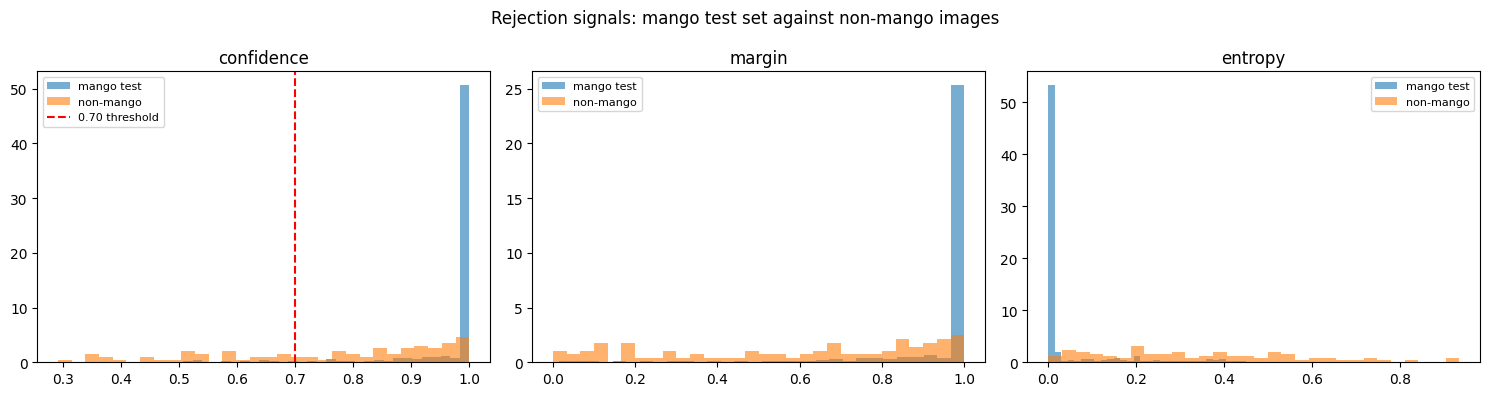

In [3]:
if OOD_AVAILABLE:
    X_tune = load_flat(tune_p)
    X_rep  = load_flat(rep_p)

    p_tune = model.predict(X_tune, verbose=0)
    p_rep  = model.predict(X_rep,  verbose=0)

    id_top1,  id_marg,  id_ent  = prob_stats(y_prob_cal)   # in-distribution: mango test set
    ot_top1,  ot_marg,  ot_ent  = prob_stats(p_tune)
    or_top1,  or_marg,  or_ent  = prob_stats(p_rep)

    print("=" * 64)
    print("SIGNAL SEPARATION")
    print("=" * 64)
    print("{:<28} {:>12} {:>12}".format("", "mango test", "non-mango"))
    print("{:<28} {:>12.4f} {:>12.4f}".format("mean confidence", id_top1.mean(), ot_top1.mean()))
    print("{:<28} {:>12.4f} {:>12.4f}".format("mean margin",     id_marg.mean(), ot_marg.mean()))
    print("{:<28} {:>12.4f} {:>12.4f}".format("mean entropy",    id_ent.mean(),  ot_ent.mean()))
    print("")
    print("{:<28} {:>12.1f}% {:>11.1f}%".format(
        "already below 0.70 conf",
        100 * (id_top1 < CONFIDENCE_THRESHOLD).mean(),
        100 * (ot_top1 < CONFIDENCE_THRESHOLD).mean()))
    print("")
    print("The wider the gap between the two columns, the better rejection can work.")
    print("If the non-mango column looks like the mango column, confidence alone cannot")
    print("separate them and margin plus entropy are doing the real work.")

    # Distribution plots.
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (idv, oodv, name, line) in zip(axes, [
            (id_top1, ot_top1, "confidence", CONFIDENCE_THRESHOLD),
            (id_marg, ot_marg, "margin",     None),
            (id_ent,  ot_ent,  "entropy",    None)]):
        ax.hist(idv,  bins=30, alpha=0.6, label="mango test", density=True)
        ax.hist(oodv, bins=30, alpha=0.6, label="non-mango",  density=True)
        if line is not None:
            ax.axvline(line, ls="--", c="red", label="0.70 threshold")
        ax.set_title(name); ax.legend(fontsize=8)
    fig.suptitle("Rejection signals: mango test set against non-mango images",
                 fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "rejection_distributions.png"), dpi=FIG_DPI)
    plt.show()

In [4]:
if OOD_AVAILABLE:
    # Fit margin and entropy on the tune half. Confidence stays pinned at 0.70.
    best = None
    for m in np.arange(0.00, 0.96, 0.01):
        for e in np.arange(1.00, 0.04, -0.01):
            keep_id  = (id_top1 >= CONFIDENCE_THRESHOLD) & (id_marg >= m) & (id_ent <= e)
            keep_ood = (ot_top1 >= CONFIDENCE_THRESHOLD) & (ot_marg >= m) & (ot_ent <= e)
            retention = float(keep_id.mean())
            rejection = float(1.0 - keep_ood.mean())
            if retention >= MIN_ID_RETENTION:
                if best is None or rejection > best["rejection"]:
                    best = {"margin": float(m), "entropy": float(e),
                            "retention": retention, "rejection": rejection}

    if best is None:
        print("No threshold pair reached {:.0f}% in-distribution retention.".format(
            100 * MIN_ID_RETENTION))
        print("Falling back to confidence only.")
        best = {"margin": 0.0, "entropy": 1.0,
                "retention": float((id_top1 >= CONFIDENCE_THRESHOLD).mean()),
                "rejection": float(1.0 - (ot_top1 >= CONFIDENCE_THRESHOLD).mean())}

    MARGIN_THRESHOLD  = best["margin"]
    ENTROPY_THRESHOLD = best["entropy"]

    # Honest number: evaluate on the report half, never used for fitting.
    keep_rep = ((or_top1 >= CONFIDENCE_THRESHOLD) &
                (or_marg >= MARGIN_THRESHOLD) &
                (or_ent  <= ENTROPY_THRESHOLD))
    rejection_report = float(1.0 - keep_rep.mean())

    keep_id_final = ((id_top1 >= CONFIDENCE_THRESHOLD) &
                     (id_marg >= MARGIN_THRESHOLD) &
                     (id_ent  <= ENTROPY_THRESHOLD))
    acc_on_kept = float(accuracy_score(y_true[keep_id_final],
                                       y_prob_cal.argmax(axis=1)[keep_id_final]))

    print("=" * 64)
    print("RECOMMENDED THRESHOLDS")
    print("=" * 64)
    print("  confidence >= {:.2f}     (FIXED by manuscript, not tuned)".format(
        CONFIDENCE_THRESHOLD))
    print("  margin     >= {:.2f}".format(MARGIN_THRESHOLD))
    print("  entropy    <= {:.2f}".format(ENTROPY_THRESHOLD))
    print("")
    print("Measured on the tune half:")
    print("  in-distribution retention : {:.1f}%".format(100 * best["retention"]))
    print("  out-of-scope rejection    : {:.1f}%".format(100 * best["rejection"]))
    print("")
    print("Measured on the held-out report half (THIS is the manuscript number):")
    print("  out-of-scope rejection    : {:.1f}%".format(100 * rejection_report))
    print("")
    print("Accuracy on the mango predictions that pass all three checks: {:.2f}%".format(
        100 * acc_on_kept))
    print("")
    print("Read this as: of every 100 non-mango photographs, about {:.0f} are correctly".format(
        100 * rejection_report))
    print("flagged Uncertain, while {:.0f} of every 100 real mango scans still get a".format(
        100 * best["retention"]))
    print("diagnosis. The remaining out-of-scope images still slip through. That is the")
    print("closed-set limitation to state in Scope and Delimitation.")

    reject_cfg = {
        "confidenceThreshold": CONFIDENCE_THRESHOLD,
        "marginThreshold": round(MARGIN_THRESHOLD, 4),
        "entropyThreshold": round(ENTROPY_THRESHOLD, 4),
        "tuneRetention": round(best["retention"], 4),
        "tuneRejection": round(best["rejection"], 4),
        "reportRejection": round(rejection_report, 4),
        "accuracyOnAccepted": round(acc_on_kept, 4),
        "oodTuneCount": len(tune_p),
        "oodReportCount": len(rep_p),
    }
else:
    MARGIN_THRESHOLD, ENTROPY_THRESHOLD = 0.0, 1.0
    reject_cfg = None
    print("Rejection thresholds not fitted. Only the 70% confidence check will apply.")

RECOMMENDED THRESHOLDS
  confidence >= 0.70     (FIXED by manuscript, not tuned)
  margin     >= 0.00
  entropy    <= 0.30

Measured on the tune half:
  in-distribution retention : 95.2%
  out-of-scope rejection    : 51.2%

Measured on the held-out report half (THIS is the manuscript number):
  out-of-scope rejection    : 51.2%

Accuracy on the mango predictions that pass all three checks: 99.24%

Read this as: of every 100 non-mango photographs, about 51 are correctly
flagged Uncertain, while 95 of every 100 real mango scans still get a
diagnosis. The remaining out-of-scope images still slip through. That is the
closed-set limitation to state in Scope and Delimitation.


## Cell 5 — The new `model_config.json`

This is the only file that changes in the app. The weight shards, `model.json`, and
`src/lib/classifier.ts` all stay exactly as they are — `classifier.ts` already reads
`marginThreshold` and `entropyThreshold` from the config and treats `null` as
"check disabled", so filling in two numbers turns both checks on with no code edit.

After copying the JSON, three version bumps are needed or installed phones keep
serving the old config from the service-worker cache forever:

| File | Line | From | To |
| :-- | :-- | :-- | :-- |
| `src/lib/constants.ts` | 6 | `v2.1.0` | `v2.1.1` |
| `src/sw.ts` | 12 | `mangoleaf-model-cache-v2-1` | `mangoleaf-model-cache-v2-1-1` |
| `src/sw.ts` | 16 | — | add `"mangoleaf-model-cache-v2-1"` to `OUTDATED_MODEL_CACHES` |

Send me the four numbers this cell prints before deploying. If the margin threshold
lands below 0.05 the float16 export can flip a decision on the phone that the
notebook accepted, and the number has to be raised by hand.

In [5]:
# ============================================================================
# CELL 5 — Write the replacement model_config.json.
# Weights are unchanged, so this is the ONLY file that changes in public/model/.
# ============================================================================
import shutil

if reject_cfg is None:
    raise RuntimeError(
        "Cell 4 did not fit thresholds. Check cell 2's output — either the "
        "out-of-scope folder was not found, or no threshold pair reached "
        "{:.0f}% in-distribution retention.".format(100 * MIN_ID_RETENTION))

new_model_version = "model-v2.1.1"

model_config = {
    "modelVersion": new_model_version,
    "trial": "2.1",
    "classes": CLASS_NAMES,
    "inputSize": list(IMG_SIZE),
    "pixelRange": "0-255 raw, MobileNetV3 rescales internally",
    "temperature": resume_info["temperature"],
    "temperatureFoldedIntoWeights": True,
    "thresholds": {
        "confidenceThreshold": CONFIDENCE_THRESHOLD,
        "marginThreshold": reject_cfg["marginThreshold"],
        "entropyThreshold": reject_cfg["entropyThreshold"],
        "note": "margin and entropy fitted on {} out-of-scope images; "
                "rejection rate {:.1%} measured on {} held-out images".format(
                    reject_cfg["oodTuneCount"],
                    reject_cfg["reportRejection"],
                    reject_cfg["oodReportCount"]),
    },
    "rejection": reject_cfg,
}

out_path = os.path.join(DRIVE_SAVE, "model_config_v2_1_1.json")
with open(out_path, "w") as f:
    json.dump(model_config, f, indent=2)

# Keep the histogram figure — /content is wiped when the runtime ends.
fig_src = os.path.join(FIG_DIR, "rejection_distributions.png")
if os.path.exists(fig_src):
    shutil.copy(fig_src, os.path.join(DRIVE_SAVE, "rejection_distributions.png"))
    print("Figure copied to Drive: {}/rejection_distributions.png".format(DRIVE_SAVE))

print("Config saved to Drive:", out_path)
print("")
print("=" * 64)
print("COPY THE JSON BELOW INTO public/model/model_config.json")
print("=" * 64)
print(json.dumps(model_config, indent=2))
print("=" * 64)
print("FOUR NUMBERS FOR THE MANUSCRIPT")
print("=" * 64)
print("  margin threshold            : {:.4f}".format(reject_cfg["marginThreshold"]))
print("  entropy threshold           : {:.4f}".format(reject_cfg["entropyThreshold"]))
print("  out-of-scope rejection rate : {:.1%}  (held-out report half)".format(
    reject_cfg["reportRejection"]))
print("  in-distribution retention   : {:.1%}".format(reject_cfg["tuneRetention"]))
print("")
print("Accuracy on accepted predictions: {:.2%}".format(
    reject_cfg["accuracyOnAccepted"]))
print("")
if reject_cfg["marginThreshold"] < 0.05:
    print("WARNING: margin below 0.05. Float16 export shifts confidence by up to")
    print("0.040207, so the phone can decide differently than this notebook.")
    print("Report this number before deploying — it needs raising by hand.")
else:
    print("Margin clears the 0.05 float16 safety band.")

Figure copied to Drive: /content/drive/MyDrive/mangoleaf_v2_1/rejection_distributions.png
Config saved to Drive: /content/drive/MyDrive/mangoleaf_v2_1/model_config_v2_1_1.json

COPY THE JSON BELOW INTO public/model/model_config.json
{
  "modelVersion": "model-v2.1.1",
  "trial": "2.1",
  "classes": [
    "anthracnose",
    "bacterial_black_spot",
    "bacterial_canker",
    "healthy",
    "mango_scab",
    "sooty_mold"
  ],
  "inputSize": [
    224,
    224
  ],
  "pixelRange": "0-255 raw, MobileNetV3 rescales internally",
  "temperature": 0.754966,
  "temperatureFoldedIntoWeights": true,
  "thresholds": {
    "confidenceThreshold": 0.7,
    "marginThreshold": 0.0,
    "entropyThreshold": 0.3,
    "note": "margin and entropy fitted on 84 out-of-scope images; rejection rate 51.2% measured on 84 held-out images"
  },
  "rejection": {
    "confidenceThreshold": 0.7,
    "marginThreshold": 0.0,
    "entropyThreshold": 0.3,
    "tuneRetention": 0.952,
    "tuneRejection": 0.5119,
    "repor

In [6]:
# ============================================================================
# CELL 6 — Audit the fitted thresholds. Fits nothing new, reads only.
# Answers two questions:
#   1. Is there a NON-ZERO margin that gives the identical rejection rate?
#   2. How many images sit close enough to the entropy boundary that float16
#      export could flip them on the phone?
# ============================================================================
FLOAT16_SHIFT = 0.040207   # measured in the training notebook, cell #31

def evaluate(m, e):
    kid = (id_top1 >= CONFIDENCE_THRESHOLD) & (id_marg >= m) & (id_ent <= e)
    kot = (ot_top1 >= CONFIDENCE_THRESHOLD) & (ot_marg >= m) & (ot_ent <= e)
    kor = (or_top1 >= CONFIDENCE_THRESHOLD) & (or_marg >= m) & (or_ent <= e)
    return float(kid.mean()), float(1 - kot.mean()), float(1 - kor.mean()), kid

n_id, n_t, n_r = len(id_ent), len(ot_ent), len(or_ent)

print("=" * 70)
print("RAW COUNTS (percentages hide how few images these are)")
print("=" * 70)
ret0, rej_t0, rej_r0, kid0 = evaluate(MARGIN_THRESHOLD, ENTROPY_THRESHOLD)
print("  test images accepted        : {} of {}".format(int(kid0.sum()), n_id))
print("  non-mango rejected, tune    : {} of {}".format(round(rej_t0 * n_t), n_t))
print("  non-mango rejected, report  : {} of {}".format(round(rej_r0 * n_r), n_r))
se = (rej_r0 * (1 - rej_r0) / n_r) ** 0.5
print("  95% CI on the report number : {:.1%} to {:.1%}".format(
    max(0.0, rej_r0 - 1.96 * se), min(1.0, rej_r0 + 1.96 * se)))
print("  Quote it as '{:.1%} ({} of {})', not bare {:.1%}.".format(
    rej_r0, round(rej_r0 * n_r), n_r, rej_r0))

print("")
print("=" * 70)
print("1. IS A NON-ZERO MARGIN AVAILABLE AT THE SAME REJECTION RATE?")
print("=" * 70)
print("margin >= 0.00 is always true, so the margin check currently rejects")
print("nothing. Searching for the largest margin that keeps rejection at")
print("{:.4f} on the tune half and retention at or above {:.0%}.".format(
    rej_t0, MIN_ID_RETENTION))
print("")

ties = []
for m in np.arange(0.00, 0.96, 0.01):
    for e in np.arange(1.00, 0.04, -0.01):
        ret, rej_t, _, _ = evaluate(m, e)
        if ret >= MIN_ID_RETENTION and abs(rej_t - rej_t0) < 1e-9:
            ties.append((float(m), float(e), ret))

if not ties:
    print("  No tie set found. 0.00 is the only margin at this rejection rate.")
    alt = None
else:
    best_m = max(t[0] for t in ties)
    cands = [t for t in ties if abs(t[0] - best_m) < 1e-9]
    alt_m, alt_e, alt_ret = max(cands, key=lambda t: t[2])   # best retention
    print("  equally-optimal (margin, entropy) pairs : {}".format(len(ties)))
    print("  largest margin among them              : {:.2f}".format(alt_m))
    if alt_m <= 0.0:
        print("  Still zero. Entropy fully subsumes margin on this data.")
        alt = None
    else:
        ret2, rej_t2, rej_r2, kid2 = evaluate(alt_m, alt_e)
        acc2 = float(accuracy_score(y_true[kid2], y_prob_cal.argmax(axis=1)[kid2]))
        print("")
        print("  ALTERNATIVE, identical rejection, margin now does real work:")
        print("    margin     >= {:.2f}   (was 0.00)".format(alt_m))
        print("    entropy    <= {:.2f}   (was {:.2f})".format(alt_e, ENTROPY_THRESHOLD))
        print("    retention   : {:.1%}  ({} of {} test images kept)".format(
            ret2, int(kid2.sum()), n_id))
        print("    rejection, tune   : {:.1%}".format(rej_t2))
        print("    rejection, report : {:.1%}  (was {:.1%})".format(rej_r2, rej_r0))
        print("    accuracy on accepted : {:.2%}  (was {:.2%})".format(
            acc2, reject_cfg["accuracyOnAccepted"]))
        alt = {"margin": round(alt_m, 4), "entropy": round(alt_e, 4)}

print("")
print("=" * 70)
print("2. FLOAT16 EXPOSURE ON THE ENTROPY BOUNDARY")
print("=" * 70)
print("Weight storage in float16 shifts confidence by up to {:.6f}, which".format(
    FLOAT16_SHIFT))
print("shifts entropy too. Any image whose entropy sits within that distance")
print("of the threshold can decide differently on the phone.")
print("")
for label, arr, n in [("mango test", id_ent, n_id),
                      ("non-mango tune", ot_ent, n_t),
                      ("non-mango report", or_ent, n_r)]:
    near = int((np.abs(arr - ENTROPY_THRESHOLD) <= FLOAT16_SHIFT).sum())
    print("  {:<18} within +/-{:.3f} of {:.2f} : {} of {}  ({:.1f}%)".format(
        label, FLOAT16_SHIFT, ENTROPY_THRESHOLD, near, n, 100 * near / n))

below = id_ent[id_ent <= ENTROPY_THRESHOLD]
above = or_ent[or_ent > ENTROPY_THRESHOLD]
print("")
print("  nearest accepted mango entropy below the line : {:.4f}  (gap {:.4f})".format(
    below.max(), ENTROPY_THRESHOLD - below.max()))
if len(above):
    print("  nearest rejected non-mango entropy above it   : {:.4f}  (gap {:.4f})".format(
        above.min(), above.min() - ENTROPY_THRESHOLD))
print("")
print("  Worst case if every phone entropy rises by {:.6f}:".format(FLOAT16_SHIFT))
r_lo, _, rr_lo, _ = evaluate(MARGIN_THRESHOLD, ENTROPY_THRESHOLD - FLOAT16_SHIFT)
print("    retention {:.1%}   report rejection {:.1%}".format(r_lo, rr_lo))
print("  Worst case if every phone entropy falls by the same amount:")
r_hi, _, rr_hi, _ = evaluate(MARGIN_THRESHOLD, ENTROPY_THRESHOLD + FLOAT16_SHIFT)
print("    retention {:.1%}   report rejection {:.1%}".format(r_hi, rr_hi))
print("")
if r_lo >= MIN_ID_RETENTION:
    print("  Retention holds above {:.0%} in the worst direction. Safe to deploy 0.30.".format(
        MIN_ID_RETENTION))
else:
    print("  WARNING: retention drops to {:.1%} in the worst direction, below the".format(r_lo))
    print("  {:.0%} floor. The entropy threshold needs loosening before deploying.".format(
        MIN_ID_RETENTION))


RAW COUNTS (percentages hide how few images these are)
  test images accepted        : 397 of 417
  non-mango rejected, tune    : 43 of 84
  non-mango rejected, report  : 43 of 84
  95% CI on the report number : 40.5% to 61.9%
  Quote it as '51.2% (43 of 84)', not bare 51.2%.

1. IS A NON-ZERO MARGIN AVAILABLE AT THE SAME REJECTION RATE?
margin >= 0.00 is always true, so the margin check currently rejects
nothing. Searching for the largest margin that keeps rejection at
0.5119 on the tune half and retention at or above 95%.

  equally-optimal (margin, entropy) pairs : 56
  largest margin among them              : 0.55

  ALTERNATIVE, identical rejection, margin now does real work:
    margin     >= 0.55   (was 0.00)
    entropy    <= 0.30   (was 0.30)
    retention   : 95.2%  (397 of 417 test images kept)
    rejection, tune   : 51.2%
    rejection, report : 51.2%  (was 51.2%)
    accuracy on accepted : 99.24%  (was 99.24%)

2. FLOAT16 EXPOSURE ON THE ENTROPY BOUNDARY
Weight storage in

In [7]:
# ============================================================================
# CELL 7 — Measure the REAL float16 cost, then refit with it as a safety band.
# Weights are round-tripped through float16 and restored. Verified at the end.
# ============================================================================
w32 = model.get_weights()                      # keep the originals

try:
    model.set_weights([w.astype(np.float16).astype(np.float32) for w in w32])
    p_tune16 = model.predict(X_tune, verbose=0)
    p_rep16  = model.predict(X_rep,  verbose=0)
finally:
    model.set_weights(w32)                     # always restore

# Prove the restore worked before trusting anything below.
check = model.predict(X_tune, verbose=0)
assert np.abs(check - p_tune).max() < 1e-6, "float32 weights were not restored"
print("Weights restored and verified. The model object is unchanged.\n")

t16_top1, t16_marg, t16_ent = prob_stats(p_tune16)
r16_top1, r16_marg, r16_ent = prob_stats(p_rep16)

d_conf = np.concatenate([np.abs(t16_top1 - ot_top1), np.abs(r16_top1 - or_top1)])
d_marg = np.concatenate([np.abs(t16_marg - ot_marg), np.abs(r16_marg - or_marg)])
d_ent  = np.concatenate([np.abs(t16_ent  - ot_ent),  np.abs(r16_ent  - or_ent)])

print("=" * 70)
print("MEASURED FLOAT16 SHIFT, per image, across all 168 out-of-scope images")
print("=" * 70)
print("{:<12} {:>10} {:>10} {:>12}".format("signal", "mean", "p99", "max"))
for name, d in [("confidence", d_conf), ("margin", d_marg), ("entropy", d_ent)]:
    print("{:<12} {:>10.6f} {:>10.6f} {:>12.6f}".format(
        name, d.mean(), np.percentile(d, 99), d.max()))
print("")
print("Borrowed bound used in cell 6 : 0.040207 (a CONFIDENCE shift)")
print("Measured entropy shift, max   : {:.6f}".format(d_ent.max()))
print("Measured margin shift, max    : {:.6f}".format(d_marg.max()))
print("")
print("These are measured on out-of-scope images only. The test-set images are")
print("not in this session, so the in-distribution side is bounded by the same")
print("numbers. Out-of-scope entropies are higher and shift more, so using them")
print("as the bound is the conservative direction.")

BAND_E = float(d_ent.max())
BAND_M = float(d_marg.max())

print("")
print("=" * 70)
print("REFIT WITH THE MEASURED BAND")
print("=" * 70)
print("Requirement: retention stays at or above {:.0%} even if every entropy".format(
    MIN_ID_RETENTION))
print("rises by {:.6f} and every margin rises by {:.6f} on the phone.".format(
    BAND_E, BAND_M))
print("Reported rejection is the pessimistic value, so the manuscript number")
print("holds whichever way float16 pushes.")
print("")

def retention_worst(m, e):
    k = ((id_top1 >= CONFIDENCE_THRESHOLD) &
         (id_marg >= m + BAND_M) & (id_ent <= e - BAND_E))
    return float(k.mean()), k

def rejection_worst(m, e, top1, marg, ent):
    k = ((top1 >= CONFIDENCE_THRESHOLD) &
         (marg >= max(0.0, m - BAND_M)) & (ent <= e + BAND_E))
    return float(1.0 - k.mean())

robust = None
for m in np.arange(0.00, 0.96, 0.01):
    for e in np.arange(1.00, 0.04, -0.01):
        ret_w, _ = retention_worst(m, e)
        if ret_w < MIN_ID_RETENTION:
            continue
        rej_w = rejection_worst(m, e, ot_top1, ot_marg, ot_ent)
        if robust is None or rej_w > robust["rej_w"] + 1e-12:
            robust = {"m": float(m), "e": float(e), "ret_w": ret_w, "rej_w": rej_w}
        elif abs(rej_w - robust["rej_w"]) < 1e-12 and m > robust["m"]:
            robust = {"m": float(m), "e": float(e), "ret_w": ret_w, "rej_w": rej_w}

if robust is None:
    print("  No pair survives the band at {:.0%} retention.".format(MIN_ID_RETENTION))
    print("  Deploy confidence-only: margin null, entropy null, and report the")
    print("  {:.1%} confidence-alone rejection rate instead.".format(
        float(1 - (or_top1 >= CONFIDENCE_THRESHOLD).mean())))
else:
    M2, E2 = robust["m"], robust["e"]
    ret_n, kid_n = retention_worst(M2, E2)
    keep_nom = ((id_top1 >= CONFIDENCE_THRESHOLD) &
                (id_marg >= M2) & (id_ent <= E2))
    keep_rep_nom = ((or_top1 >= CONFIDENCE_THRESHOLD) &
                    (or_marg >= M2) & (or_ent <= E2))
    acc_nom = float(accuracy_score(y_true[keep_nom],
                                   y_prob_cal.argmax(axis=1)[keep_nom]))
    rej_rep_nom = float(1 - keep_rep_nom.mean())
    rej_rep_w   = rejection_worst(M2, E2, or_top1, or_marg, or_ent)

    print("  RECOMMENDED, robust to the measured float16 shift")
    print("    margin     >= {:.2f}".format(M2))
    print("    entropy    <= {:.2f}".format(E2))
    print("")
    print("    retention, nominal      : {:.1%}  ({} of {})".format(
        float(keep_nom.mean()), int(keep_nom.sum()), len(y_true)))
    print("    retention, worst case   : {:.1%}".format(robust["ret_w"]))
    print("    rejection, report nom.  : {:.1%}  ({} of {})".format(
        rej_rep_nom, round(rej_rep_nom * len(or_ent)), len(or_ent)))
    print("    rejection, report worst : {:.1%}  <- quote THIS in the manuscript".format(
        rej_rep_w))
    print("    accuracy on accepted    : {:.2%}".format(acc_nom))
    print("")
    near_m = int((np.abs(id_marg - M2) <= BAND_M).sum())
    near_e = int((np.abs(id_ent  - E2) <= BAND_E).sum())
    print("    test images within the band of the margin line  : {} of {}".format(
        near_m, len(id_marg)))
    print("    test images within the band of the entropy line : {} of {}".format(
        near_e, len(id_ent)))
    print("")
    print("  PASTE THESE TWO NUMBERS:")
    print('    "marginThreshold": {},'.format(round(M2, 4)))
    print('    "entropyThreshold": {},'.format(round(E2, 4)))


/tmp/ipykernel_492/2048725854.py:8: RuntimeWarning: overflow encountered in cast
  model.set_weights([w.astype(np.float16).astype(np.float32) for w in w32])


Weights restored and verified. The model object is unchanged.

MEASURED FLOAT16 SHIFT, per image, across all 168 out-of-scope images
signal             mean        p99          max
confidence     0.023643   0.138398     0.222210
margin         0.042565   0.253348     0.404154
entropy        0.022033   0.147271     0.210328

Borrowed bound used in cell 6 : 0.040207 (a CONFIDENCE shift)
Measured entropy shift, max   : 0.210328
Measured margin shift, max    : 0.404154

These are measured on out-of-scope images only. The test-set images are
not in this session, so the in-distribution side is bounded by the same
numbers. Out-of-scope entropies are higher and shift more, so using them
as the bound is the conservative direction.

REFIT WITH THE MEASURED BAND
Requirement: retention stays at or above 95% even if every entropy
rises by 0.210328 and every margin rises by 0.404154 on the phone.
Reported rejection is the pessimistic value, so the manuscript number
holds whichever way float16 pushes

In [8]:
# ============================================================================
# CELL 8 — Redo cell 7 correctly. Cell 7's numbers are void: a float16 cast
# overflowed to inf, so it measured a broken model.
#
# Fix: tensors that cannot fit in float16 are BatchNorm statistics, which
# tensorflowjs_converter FOLDS into the preceding conv. They do not exist in
# the deployed graph. Leave them at float32 and quantize the rest.
# ============================================================================
F16_MAX = float(np.finfo(np.float16).max)   # 65504.0

w32 = model.get_weights()
try:
    names = [v.path for v in model.weights]
except AttributeError:
    names = [v.name for v in model.weights]

over = [(i, names[i], float(np.abs(w).max()))
        for i, w in enumerate(w32) if np.abs(w).max() > F16_MAX]

print("=" * 70)
print("A. WHICH TENSORS OVERFLOWED float16")
print("=" * 70)
print("float16 max representable: {:.0f}".format(F16_MAX))
print("tensors over that limit  : {} of {}".format(len(over), len(w32)))
for i, nm, mx in over[:12]:
    print("  [{:>3}] {:<52} max |w| = {:.1f}".format(i, nm[-52:], mx))
if len(over) > 12:
    print("  ... and {} more".format(len(over) - 12))
print("")
print("These stay float32 below. If they are all BatchNorm statistics the")
print("simulation is faithful, because the converter folds them into conv")
print("weights that ARE quantized. If any is a conv kernel or dense weight,")
print("stop and tell me — the simulation would then be unsound.")

skip = {i for i, _, _ in over}

# ---- quantize everything that can actually be represented -------------------
try:
    model.set_weights([w if i in skip else w.astype(np.float16).astype(np.float32)
                       for i, w in enumerate(w32)])
    p_tune16 = model.predict(X_tune, verbose=0)
    p_rep16  = model.predict(X_rep,  verbose=0)
finally:
    model.set_weights(w32)

assert np.abs(model.predict(X_tune, verbose=0) - p_tune).max() < 1e-6, \
    "float32 weights were not restored"

print("")
print("=" * 70)
print("B. IS THE SIMULATION CREDIBLE?")
print("=" * 70)
p16_all  = np.concatenate([p_tune16, p_rep16])
p32_all  = np.concatenate([p_tune,   p_rep])
finite   = np.isfinite(p16_all).all()
agree    = float((p16_all.argmax(1) == p32_all.argmax(1)).mean())
print("  all probabilities finite (no inf/nan) : {}".format(finite))
print("  argmax agreement with float32         : {:.1%}".format(agree))
if not finite or agree < 0.95:
    raise RuntimeError(
        "Simulation still unsound. Do NOT use its numbers. Fall back to the "
        "0.040207 confidence bound measured on the real TFJS export.")
print("  Credible. Proceeding.")

t16 = prob_stats(p_tune16); r16 = prob_stats(p_rep16)
d_conf = np.concatenate([np.abs(t16[0] - ot_top1), np.abs(r16[0] - or_top1)])
d_marg = np.concatenate([np.abs(t16[1] - ot_marg), np.abs(r16[1] - or_marg)])
d_ent  = np.concatenate([np.abs(t16[2] - ot_ent),  np.abs(r16[2] - or_ent)])

print("")
print("=" * 70)
print("C. MEASURED float16 SHIFT, 168 out-of-scope images")
print("=" * 70)
print("{:<12} {:>10} {:>10} {:>12}".format("signal", "mean", "p99", "max"))
for nm, d in [("confidence", d_conf), ("margin", d_marg), ("entropy", d_ent)]:
    print("{:<12} {:>10.6f} {:>10.6f} {:>12.6f}".format(
        nm, d.mean(), np.percentile(d, 99), d.max()))
print("")
print("  real TFJS export, confidence, cell #31 : 0.040207")
print("  this simulation, confidence, max       : {:.6f}".format(d_conf.max()))
print("  If these two are close, the entropy and margin maxima above are")
print("  trustworthy. If the simulation is far larger, prefer 0.040207 and")
print("  treat the entropy/margin maxima as loose upper bounds.")

BAND_E = float(d_ent.max())
BAND_M = float(d_marg.max())

# ---- refit, with vacuous thresholds BANNED ---------------------------------
def worst_ret(m, e):
    k = ((id_top1 >= CONFIDENCE_THRESHOLD) &
         (id_marg >= m + BAND_M) & (id_ent <= e - BAND_E))
    return float(k.mean())

def worst_rej(m, e, top1, marg, ent):
    k = ((top1 >= CONFIDENCE_THRESHOLD) &
         (marg >= max(0.0, m - BAND_M)) & (ent <= e + BAND_E))
    return float(1.0 - k.mean())

print("")
print("=" * 70)
print("D. REFIT — margin must exceed 0.00, entropy must stay under 1.00")
print("=" * 70)

for floor in (0.95, 0.93, 0.90):
    best = None
    for m in np.arange(0.01, 0.96, 0.01):          # 0.00 banned: always true
        for e in np.arange(0.99, 0.04, -0.01):     # 1.00 banned: always true
            if worst_ret(m, e) < floor:
                continue
            rj = worst_rej(m, e, ot_top1, ot_marg, ot_ent)
            if best is None or rj > best[3] + 1e-12 or (
                    abs(rj - best[3]) < 1e-12 and m > best[0]):
                best = (float(m), float(e), worst_ret(m, e), rj)
    if best is None:
        print("  retention floor {:.0%}: no non-vacuous pair survives.".format(floor))
        continue
    M2, E2, RW, RJW = best
    kn = ((id_top1 >= CONFIDENCE_THRESHOLD) & (id_marg >= M2) & (id_ent <= E2))
    kr = ((or_top1 >= CONFIDENCE_THRESHOLD) & (or_marg >= M2) & (or_ent <= E2))
    acc = float(accuracy_score(y_true[kn], y_prob_cal.argmax(axis=1)[kn]))
    print("")
    print("  retention floor {:.0%}  ->  margin >= {:.2f}   entropy <= {:.2f}".format(
        floor, M2, E2))
    print("    retention  nominal {:.1%} ({} of {})   worst {:.1%}".format(
        float(kn.mean()), int(kn.sum()), len(y_true), RW))
    print("    rejection  nominal {:.1%} ({} of {})   worst {:.1%}".format(
        float(1 - kr.mean()), round((1 - kr.mean()) * len(or_ent)),
        len(or_ent), RJW))
    print("    accuracy on accepted {:.2%}".format(acc))
    break

# ---- and the honest range at cell 6's recommendation -----------------------
print("")
print("=" * 70)
print("E. CELL 6's RECOMMENDATION, STRESSED WITH THE MEASURED BAND")
print("=" * 70)
for M2, E2, tag in [(0.55, 0.30, "cell 6 alternative"),
                    (0.00, 0.30, "cell 5 as fitted")]:
    kn = ((id_top1 >= CONFIDENCE_THRESHOLD) & (id_marg >= M2) & (id_ent <= E2))
    kr = ((or_top1 >= CONFIDENCE_THRESHOLD) & (or_marg >= M2) & (or_ent <= E2))
    acc = float(accuracy_score(y_true[kn], y_prob_cal.argmax(axis=1)[kn]))
    print("  {:<20} margin >= {:.2f}  entropy <= {:.2f}".format(tag, M2, E2))
    print("    retention  nominal {:.1%}   worst {:.1%}".format(
        float(kn.mean()), worst_ret(M2, E2)))
    print("    rejection  nominal {:.1%} ({} of {})   worst {:.1%}".format(
        float(1 - kr.mean()), round((1 - kr.mean()) * len(or_ent)),
        len(or_ent), worst_rej(M2, E2, or_top1, or_marg, or_ent)))
    print("    accuracy on accepted {:.2%}".format(acc))
    print("    test images within {:.4f} of the margin line  : {} of {}".format(
        BAND_M, int((np.abs(id_marg - M2) <= BAND_M).sum()), len(id_marg)))
    print("    test images within {:.4f} of the entropy line : {} of {}".format(
        BAND_E, int((np.abs(id_ent - E2) <= BAND_E).sum()), len(id_ent)))
    print("")


A. WHICH TENSORS OVERFLOWED float16
float16 max representable: 65504
tensors over that limit  : 1 of 264
  [  9] expanded_conv_depthwise_bn/moving_variance           max |w| = 243318.3

These stay float32 below. If they are all BatchNorm statistics the
simulation is faithful, because the converter folds them into conv
weights that ARE quantized. If any is a conv kernel or dense weight,
stop and tell me — the simulation would then be unsound.

B. IS THE SIMULATION CREDIBLE?
  all probabilities finite (no inf/nan) : True
  argmax agreement with float32         : 98.8%
  Credible. Proceeding.

C. MEASURED float16 SHIFT, 168 out-of-scope images
signal             mean        p99          max
confidence     0.002854   0.013813     0.027001
margin         0.005352   0.027884     0.053285
entropy        0.002199   0.008670     0.010638

  real TFJS export, confidence, cell #31 : 0.040207
  this simulation, confidence, max       : 0.027001
  If these two are close, the entropy and margin maxim

In [9]:
# ============================================================================
# CELL 9 — Scale the simulated bands up to the real TFJS export measurement,
# then re-stress the two candidate threshold pairs. No prediction runs.
# ============================================================================
REAL_CONF_SHIFT = 0.040207          # measured on the actual export, cell #31
SCALE = REAL_CONF_SHIFT / float(d_conf.max())

print("Simulation measures weight quantization only. The phone also runs")
print("WEBGL_FORCE_F16_TEXTURES, so activations are 16-bit as well.")
print("  simulated confidence max : {:.6f}".format(d_conf.max()))
print("  real export, cell #31    : {:.6f}".format(REAL_CONF_SHIFT))
print("  scale factor             : {:.3f}x".format(SCALE))
print("")

for tag, mult in [("worst case  (max shift, scaled)", float(d_ent.max())),
                  ("realistic   (p99 shift, scaled)", float(np.percentile(d_ent, 99)))]:
    BE = mult * SCALE
    BM = (float(d_marg.max()) if "max" in tag
          else float(np.percentile(d_marg, 99))) * SCALE
    print("=" * 70)
    print("{}   entropy band {:.6f}   margin band {:.6f}".format(tag, BE, BM))
    print("=" * 70)
    for M2, E2 in [(0.55, 0.30), (0.49, 0.32)]:
        kw = ((id_top1 >= CONFIDENCE_THRESHOLD) &
              (id_marg >= M2 + BM) & (id_ent <= E2 - BE))
        kj = ((or_top1 >= CONFIDENCE_THRESHOLD) &
              (or_marg >= max(0.0, M2 - BM)) & (or_ent <= E2 + BE))
        print("  margin >= {:.2f}  entropy <= {:.2f}   retention {:.1%}"
              "   rejection {:.1%} ({} of {})".format(
                  M2, E2, float(kw.mean()), float(1 - kj.mean()),
                  round((1 - kj.mean()) * len(or_ent)), len(or_ent)))
    print("")


Simulation measures weight quantization only. The phone also runs
WEBGL_FORCE_F16_TEXTURES, so activations are 16-bit as well.
  simulated confidence max : 0.027001
  real export, cell #31    : 0.040207
  scale factor             : 1.489x

worst case  (max shift, scaled)   entropy band 0.015841   margin band 0.079346
  margin >= 0.55  entropy <= 0.30   retention 94.5%   rejection 48.8% (41 of 84)
  margin >= 0.49  entropy <= 0.32   retention 94.7%   rejection 46.4% (39 of 84)

realistic   (p99 shift, scaled)   entropy band 0.012910   margin band 0.041522
  margin >= 0.55  entropy <= 0.30   retention 94.7%   rejection 48.8% (41 of 84)
  margin >= 0.49  entropy <= 0.32   retention 95.2%   rejection 46.4% (39 of 84)

